# Leaf disease segmentation: data preparation and EDA

In [27]:
from pathlib import Path
import random

import cv2
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split

SEED = 42
IMAGE_SIZE = (256, 256)
random.seed(SEED)
np.random.seed(SEED)

## 1. Load the local dataset

In [28]:
PROJECT_ROOT = Path.cwd().parent
DATASET_DIR = PROJECT_ROOT / "data"
if not DATASET_DIR.exists():
    raise FileNotFoundError(f"Dataset not found at {DATASET_DIR}")

In [29]:
# Display the downloaded folder structure.
for path in sorted(DATASET_DIR.rglob("*")):
    if path.is_dir():
        print(path.relative_to(DATASET_DIR))

images
masks


## 2. Match images and masks


In [30]:
IMAGE_DIR = DATASET_DIR / "images"
MASK_DIR = DATASET_DIR / "masks"

image_files = sorted(IMAGE_DIR.glob("*.jpg"))
mask_files = sorted(MASK_DIR.glob("*.png"))

pairs = [
    (image_path, MASK_DIR / f"{image_path.stem}.png")
    for image_path in image_files
    if (MASK_DIR / f"{image_path.stem}.png").exists()
]

print(f"Image files found: {len(image_files)}")
print(f"Mask files found:  {len(mask_files)}")
print(f"Matched pairs:     {len(pairs)}")

if len(pairs) != len(image_files):
    raise RuntimeError("Some images do not have matching masks.")

Image files found: 588
Mask files found:  588
Matched pairs:     588


### Simple EDA

In [31]:
# Inspect dimensions and mask coverage.
image_shapes = []
mask_shapes = []
disease_coverage = []

for image_path, mask_path in pairs:
    image = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
    mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
    if image is None or mask is None:
        continue
    image_shapes.append(image.shape[:2])
    mask_shapes.append(mask.shape[:2])
    disease_coverage.append((mask > 0).mean() * 100)

print(f"Unique image sizes: {len(set(image_shapes))}")
print(f"Unique mask sizes:  {len(set(mask_shapes))}")
print(f"Mean diseased area: {np.mean(disease_coverage):.2f}%")

Unique image sizes: 253
Unique mask sizes:  253
Mean diseased area: 16.27%


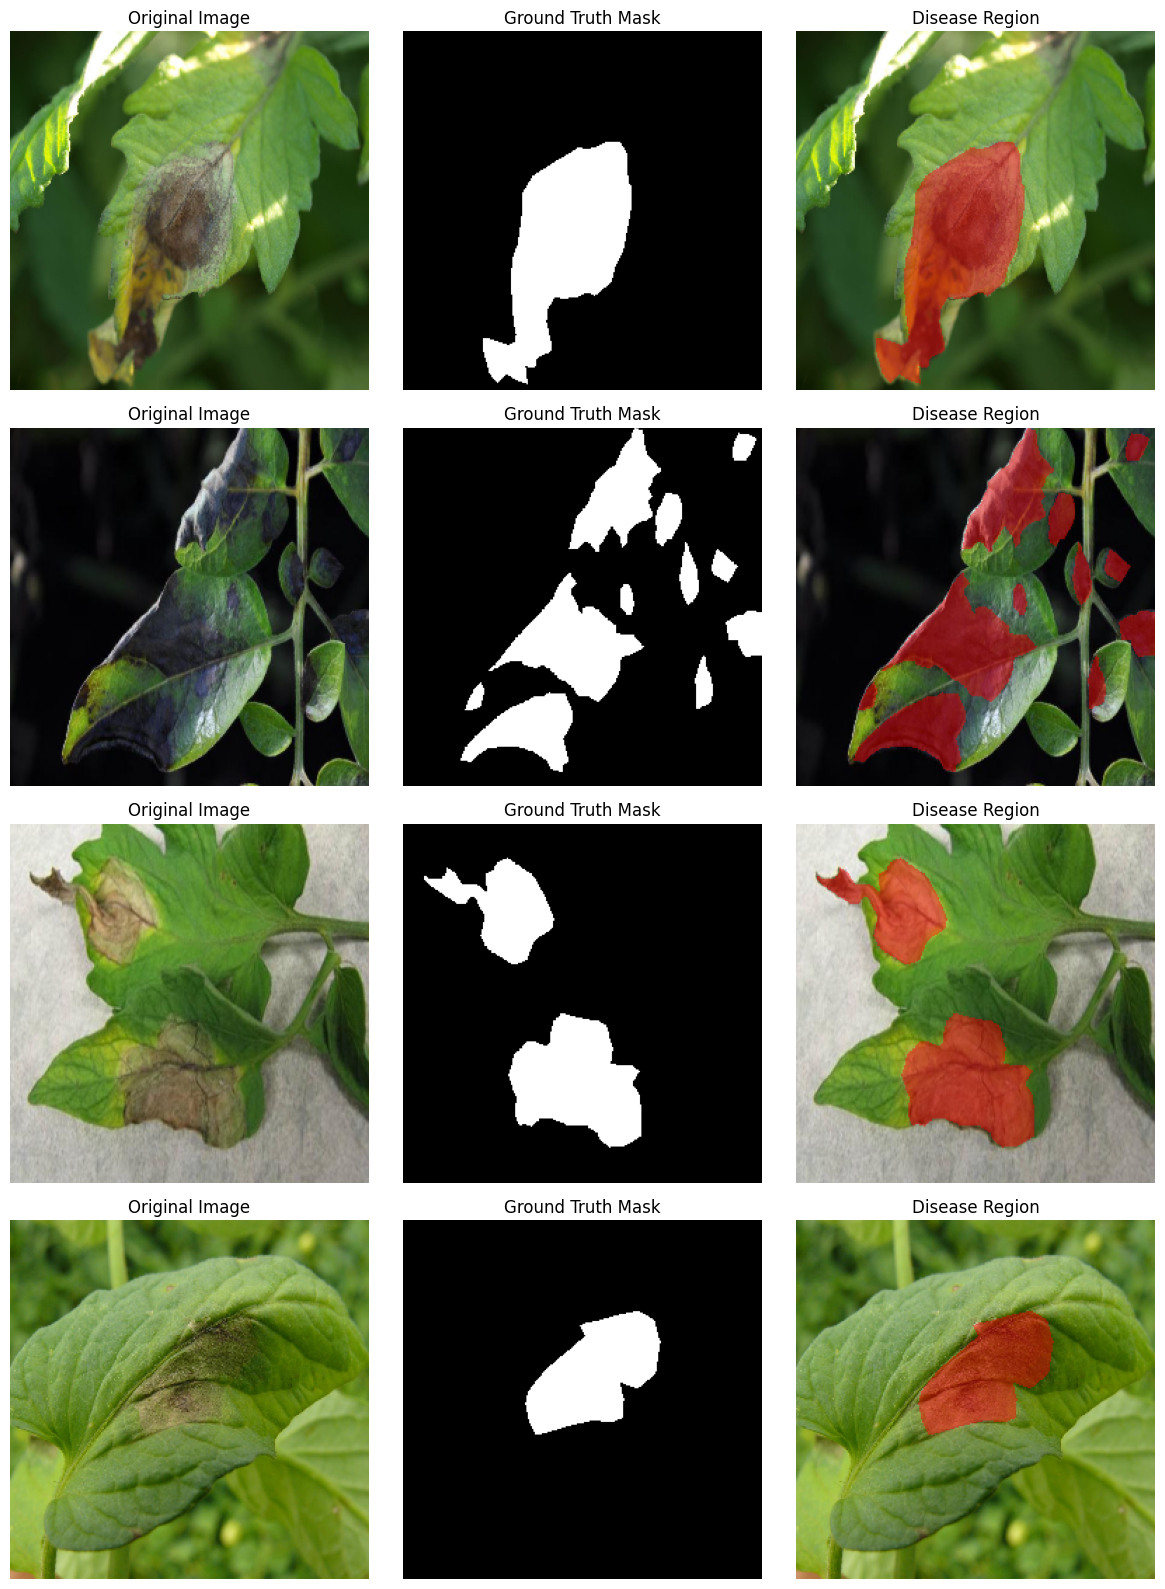

In [32]:
IMG_SIZE = 256

examples = random.sample(pairs, k=4)

fig, axes = plt.subplots(
    len(examples), 3,
    figsize=(12, 4 * len(examples)),
    squeeze=False
)

for row, (image_path, mask_path) in enumerate(examples):

    image = cv2.cvtColor(
        cv2.imread(str(image_path)),
        cv2.COLOR_BGR2RGB
    )
    mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
    image = cv2.resize(
        image, (IMG_SIZE, IMG_SIZE),
        interpolation=cv2.INTER_LINEAR
    )
    mask = cv2.resize(
        mask, (IMG_SIZE, IMG_SIZE),
        interpolation=cv2.INTER_NEAREST
    )
    disease_mask = mask > 0

    # Highlight disease regions in red
    highlighted = image.copy()
    alpha = 0.45

    highlighted[disease_mask] = (
        (1 - alpha) * image[disease_mask] +
        alpha * np.array([255, 0, 0])
    ).astype(np.uint8)

    # Display
    axes[row, 0].imshow(image)
    axes[row, 0].set_title("Original Image")

    axes[row, 1].imshow(disease_mask, cmap="gray", vmin=0, vmax=1)
    axes[row, 1].set_title("Ground Truth Mask")

    axes[row, 2].imshow(highlighted)
    axes[row, 2].set_title("Disease Region")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

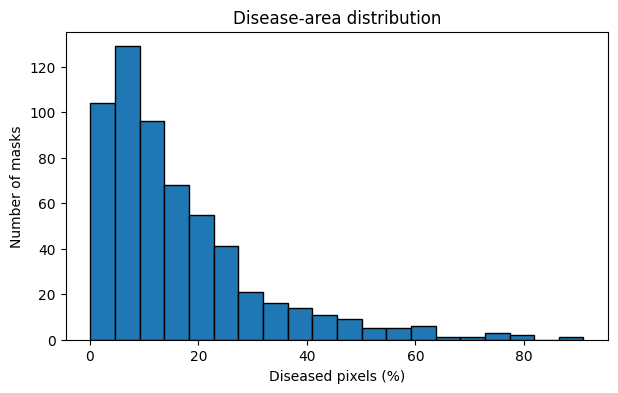

In [33]:
plt.figure(figsize=(7, 4))
plt.hist(disease_coverage, bins=20, edgecolor="black")
plt.xlabel("Diseased pixels (%)")
plt.ylabel("Number of masks")
plt.title("Disease-area distribution")
plt.show()

## 3. Create train, validation, and test sets

The original image-mask pairs are split before any training augmentation: 70% training, 15% validation, and 15% test.

In [34]:
train_pairs, remaining_pairs = train_test_split(
    pairs, test_size=0.30, random_state=SEED, shuffle=True
)
validation_pairs, test_pairs = train_test_split(
    remaining_pairs, test_size=0.50, random_state=SEED, shuffle=True
)

print(f"Training:   {len(train_pairs)}")
print(f"Validation: {len(validation_pairs)}")
print(f"Test:       {len(test_pairs)}")

Training:   411
Validation: 88
Test:       89


## 4. Resize, binarize, and save the prepared data

In [35]:
PROCESSED_DIR = DATASET_DIR / "processed"
PROCESSED_DIR.mkdir(exist_ok=True)

def prepare_and_save(split_name, split_pairs):
    image_output_dir = PROCESSED_DIR / split_name / "images"
    mask_output_dir = PROCESSED_DIR / split_name / "masks"
    image_output_dir.mkdir(parents=True, exist_ok=True)
    mask_output_dir.mkdir(parents=True, exist_ok=True)

    for image_path, mask_path in split_pairs:
        image = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
        mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
        resized_image = cv2.resize(
            image, IMAGE_SIZE, interpolation=cv2.INTER_AREA
        )
        resized_mask = cv2.resize(
            mask, IMAGE_SIZE, interpolation=cv2.INTER_NEAREST
        )
        binary_mask = ((resized_mask > 0) * 255).astype(np.uint8)

        output_name = f"{image_path.stem}.png"
        cv2.imwrite(str(image_output_dir / output_name), resized_image)
        cv2.imwrite(str(mask_output_dir / output_name), binary_mask)

    print(f"Saved {split_name}: {len(split_pairs)} image-mask pairs")

prepare_and_save("train", train_pairs)
prepare_and_save("validation", validation_pairs)
prepare_and_save("test", test_pairs)

Saved train: 411 image-mask pairs
Saved validation: 88 image-mask pairs
Saved test: 89 image-mask pairs
